# Publish sample photos for the spec2inspect Live tray

Picks a small, labelled set of MVTec LOCO **pushpins** test photos (good boxes and logical anomalies, including
the missing-wall boxes), adds a few **colour variants** (the same boxes with blue, red, purple, green or mixed-colour
pins, for trying the colour rules), converts them to JPEG, writes a dataset card, and uploads them to the **public**
Hugging Face dataset that the line page's Live tray reads (`saiphyohein/spec2inspect-images`).

**Kaggle setup:** Internet on (no GPU needed). Secrets:
- `HF_TOKEN`: reads the private source dataset (`saiphyohein/builder-cup`)
- `HF_TOKEN` needs **write** access, because the photos are uploaded to the same `saiphyohein` account
  (optional: a separate `HF_WRITE_TOKEN` secret is used for the upload if you add one).

The photos stay under their original licence, **CC BY-NC-SA 4.0** (MVTec LOCO AD): non-commercial, share-alike,
with attribution. The dataset card says so.

In [1]:
!pip install -q huggingface_hub

## Settings

In [2]:
import os, random, tarfile, csv, io
from pathlib import Path
from PIL import Image

SRC_REPO, SRC_FILE = "saiphyohein/builder-cup", "pushpins.tar.xz"     # private: the full category archive
DST_REPO = "saiphyohein/spec2inspect-images"                         # public: what the Live tray shows
N_GOOD = 8                                                             # good boxes
MISSING_WALL = ["067", "062", "080", "064", "076"]                     # logical anomalies with a missing wall
N_OTHER_ANOMALIES = 5                                                  # other logical anomalies (pin count)
SEED, JPEG_QUALITY = 7, 92
# Colour variants: synthetic recolouring of the pins only (walls and background stay untouched).
# Each entry: colour -> which chosen photos get it ("good:0" = first good box, "wall:0" = first missing-wall box, ...)
COLOUR_VARIANTS = {
    "Blue":           ["good:0", "wall:0"],
    "Red":            ["good:1", "other:0"],
    "Purple":         ["good:2"],
    "Green":          ["good:3"],
    "Random per pin": ["good:4", "good:5", "other:1"],   # mixed colours in one box
}
WORK, OUT = Path("/kaggle/working/src"), Path("/kaggle/working/samples")

try:
    from kaggle_secrets import UserSecretsClient
    _s = UserSecretsClient()
    READ_TOKEN = _s.get_secret("HF_TOKEN")
    try:
        WRITE_TOKEN = _s.get_secret("HF_WRITE_TOKEN")
    except Exception:
        WRITE_TOKEN = READ_TOKEN
except Exception:                                                      # outside Kaggle
    READ_TOKEN = os.environ.get("HF_TOKEN"); WRITE_TOKEN = os.environ.get("HF_WRITE_TOKEN", READ_TOKEN)
assert READ_TOKEN, "add the HF_TOKEN secret (Add-ons > Secrets)"

## Download the pushpins archive and find the test split

In [3]:
from huggingface_hub import hf_hub_download

WORK.mkdir(parents=True, exist_ok=True)
archive = hf_hub_download(SRC_REPO, SRC_FILE, repo_type="dataset", local_dir=str(WORK), token=READ_TOKEN)
with tarfile.open(archive) as t:
    t.extractall(WORK)

def find_category_dir(root, category="pushpins"):
    found = [Path(d) for d, _, _ in os.walk(root)
             if (Path(d) / "test" / "good").is_dir() and (Path(d) / "test" / "logical_anomalies").is_dir()]
    named = [d for d in found if d.name == category]
    return (named or found)[0]

CAT = find_category_dir(WORK)
good_all = sorted((CAT / "test" / "good").glob("*.png"))
anom_all = sorted((CAT / "test" / "logical_anomalies").glob("*.png"))
print(f"{CAT}: {len(good_all)} good, {len(anom_all)} logical anomalies")

pushpins.tar.xz: reconstructing file:   0%|          |  0.00B / 1.12GB            

pushpins.tar.xz: downloading bytes:           |  0.00B            

/tmp/ipykernel_48/1059961646.py:6: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  t.extractall(WORK)


/kaggle/working/src/pushpins: 138 good, 91 logical anomalies


## Choose the photos

In [4]:
rng = random.Random(SEED)
good = sorted(rng.sample(good_all, min(N_GOOD, len(good_all))))
walls = [p for p in anom_all if p.stem in MISSING_WALL]
others = [p for p in anom_all if p.stem not in MISSING_WALL]
other = sorted(rng.sample(others, min(N_OTHER_ANOMALIES, len(others))))

chosen = ([(p, "good", "good box") for p in good] +
          [(p, "anomaly", "missing wall between two compartments") for p in walls] +
          [(p, "anomaly", "logical anomaly (pin count or placement)") for p in other])
print(f"{len(chosen)} photos: {len(good)} good, {len(walls)} missing wall, {len(other)} other anomalies")

18 photos: 8 good, 5 missing wall, 5 other anomalies


## Colour variants
The pins are the only strongly coloured objects in the box, so rotating the hue of the saturated pixels recolours the
pins and leaves the grey walls and black background unchanged. This is the same edit used for the recorded
colour variants on the line page.

In [5]:
import numpy as np
from scipy import ndimage

PIN_HUES = {"Red": 0, "Green": 85, "Cyan": 128, "Blue": 165, "Purple": 195, "Pink": 225}   # PIL HSV hue (0-255)

def recolor(im, mode, seed=0):
    """Recolour the pins: one colour for all pins, or "Random per pin" for a different colour per pin."""
    hsv = np.array(im.convert("RGB").convert("HSV")).astype(np.int16)
    h, s, v = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    mask = (s > 110) & (v > 70)
    base = int(np.median(h[mask])) if mask.any() else 0
    if mode == "Random per pin":
        lab, n = ndimage.label(ndimage.binary_dilation(mask, iterations=3))
        rng = np.random.default_rng(seed)
        hues = np.array(list(PIN_HUES.values()) + [26])          # 26 = the original yellow
        target = hues[rng.integers(0, len(hues), size=n + 1)]
        h[mask] = (h[mask] - base + target[lab[mask]]) % 256
    else:
        h[mask] = (h[mask] - base + PIN_HUES[mode]) % 256
    return Image.fromarray(np.stack([h, s, v], -1).astype(np.uint8), "HSV").convert("RGB")

groups = {"good": good, "wall": walls, "other": other}
variants = []                                                # (source path, label, note, colour)
for colour, picks in COLOUR_VARIANTS.items():
    for pick in picks:
        g, i = pick.split(":"); i = int(i)
        if i < len(groups[g]):
            src = groups[g][i]
            label, note = ("good", "good box") if g == "good" else \
                          ("anomaly", "missing wall between two compartments" if g == "wall" else "logical anomaly (pin count or placement)")
            variants.append((src, label, note, colour))
print(f"{len(variants)} colour variants planned")

9 colour variants planned


## Convert to JPEG and write the metadata

In [6]:
OUT.mkdir(parents=True, exist_ok=True)
for f in OUT.glob("*"):
    f.unlink()
rows = []
for src, label, note in chosen:
    name = f"{label}_{src.stem}.jpg"                       # e.g. good_012.jpg, anomaly_067.jpg
    Image.open(src).convert("RGB").save(OUT / name, quality=JPEG_QUALITY, optimize=True)
    rows.append({"file": name, "label": label, "pins": "original yellow", "note": note,
                 "source": f"MVTec LOCO AD / pushpins / test / {src.parent.name} / {src.name}"})
for k, (src, label, note, colour) in enumerate(variants):
    tag = "mixed" if colour == "Random per pin" else colour.lower()
    name = f"{label}_{src.stem}_{tag}.jpg"                 # e.g. good_012_blue.jpg, anomaly_067_mixed.jpg
    recolor(Image.open(src), colour, seed=SEED + k).save(OUT / name, quality=JPEG_QUALITY, optimize=True)
    pins = "mixed colours" if colour == "Random per pin" else f"{colour.lower()} (synthetic recolour)"
    rows.append({"file": name, "label": label, "pins": pins, "note": note,
                 "source": f"MVTec LOCO AD / pushpins / test / {src.parent.name} / {src.name}, pins recoloured"})
with open(OUT / "metadata.csv", "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=list(rows[0])); w.writeheader(); w.writerows(rows)
size_mb = sum(p.stat().st_size for p in OUT.glob("*.jpg")) / 1e6
print(f"wrote {len(rows)} JPEGs ({size_mb:.1f} MB) + metadata.csv to {OUT}")

wrote 27 JPEGs (5.5 MB) + metadata.csv to /kaggle/working/samples


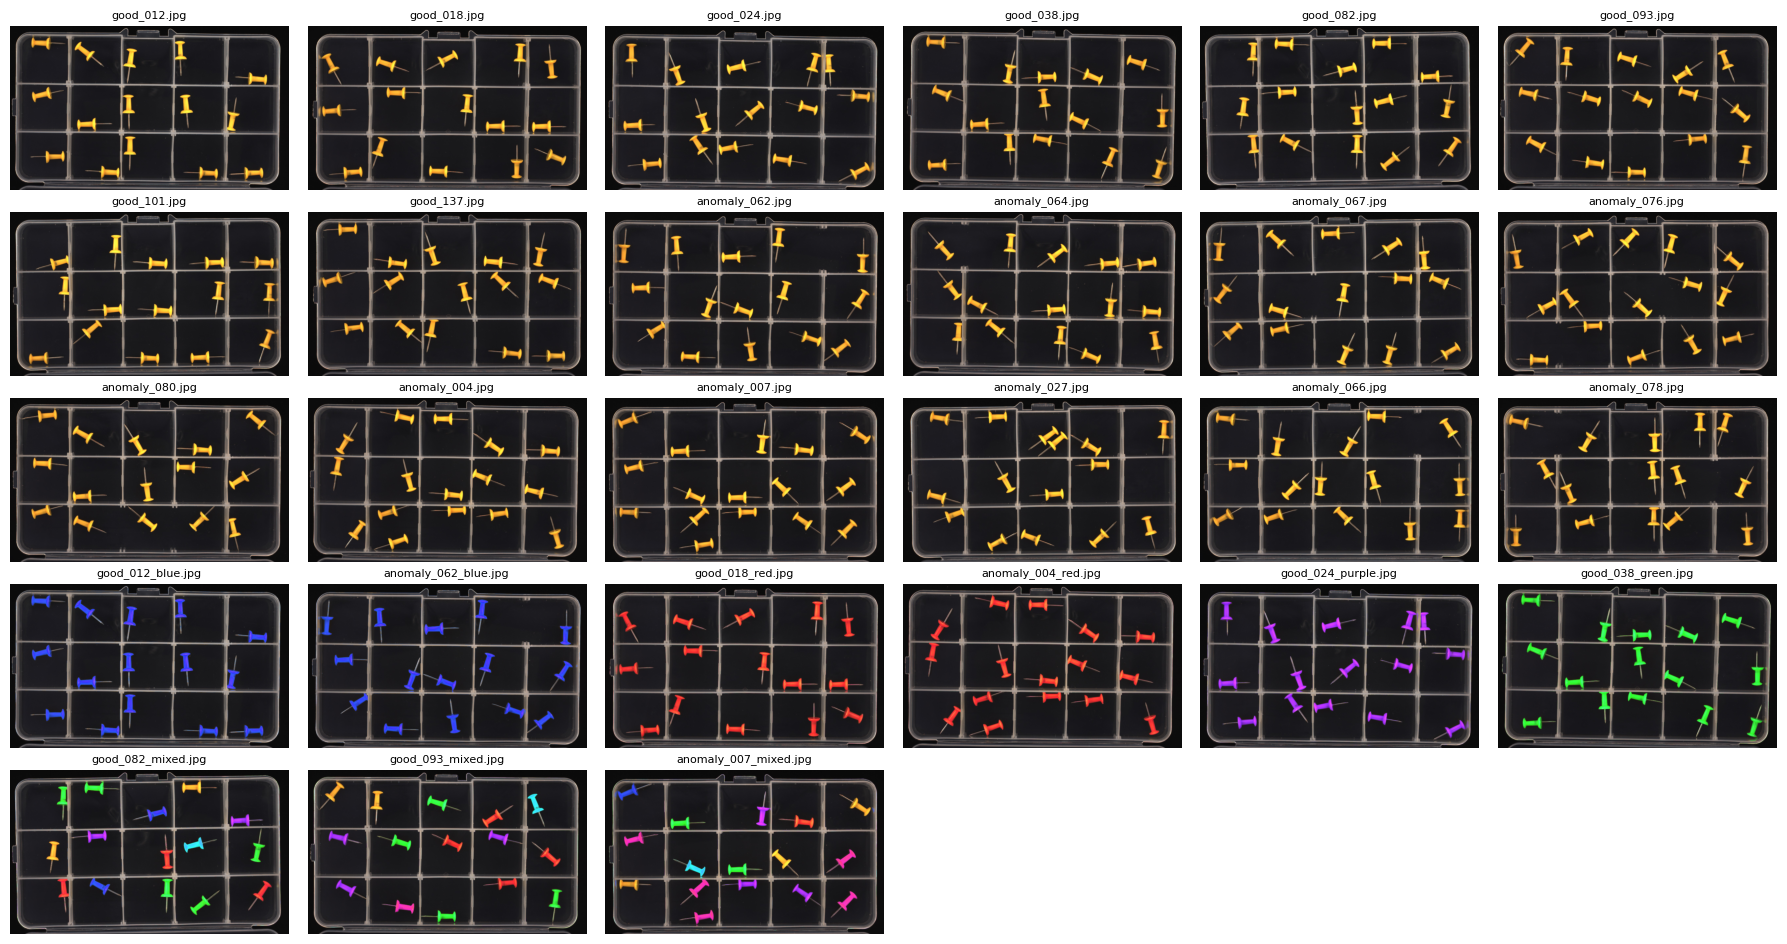

In [7]:
# Preview
import matplotlib.pyplot as plt
n = len(rows); cols = 6; r = (n + cols - 1) // cols
fig, axes = plt.subplots(r, cols, figsize=(3 * cols, 1.9 * r))
for ax in axes.flat:
    ax.axis("off")
for ax, row in zip(axes.flat, rows):
    ax.imshow(Image.open(OUT / row["file"])); ax.set_title(row["file"], fontsize=8)
plt.tight_layout(); plt.show()

## Dataset card

In [8]:
table = "\n".join(f"| `{r['file']}` | {r['label']} | {r['pins']} | {r['note']} |" for r in rows)
card = f"""---
license: cc-by-nc-sa-4.0
pretty_name: spec2inspect sample photos
task_categories:
- image-classification
tags:
- anomaly-detection
- visual-inspection
- mvtec-loco
size_categories:
- n<1K
---

# spec2inspect sample photos

A few photos of 3 x 5 pushpin boxes for trying **spec2inspect** in Live mode: drag one onto the production line
(or download it and upload it), press **Inspect**, and Gemma 4 checks it against the written specification.

Good boxes hold exactly one pushpin in every compartment, inside complete walls. The anomalies break a written rule:
a missing wall between two compartments, or a wrong number or placement of pins.

Files ending in `_blue`, `_red`, `_purple`, `_green` or `_mixed` are **colour variants**: the same photo with the pins
recoloured (synthetic edit; walls and background unchanged). They pass or fail the counting and wall rules exactly
like the original, and are there to try the colour rules, for example "Every pushpin is yellow" or
"All pushpins are the same colour".

| File | Label | Pins | What to expect |
|---|---|---|---|
{table}

`metadata.csv` lists the same labels and the original file each photo comes from.

## Source and licence

The photos are test images (converted to JPEG) from the **pushpins** category of
**MVTec LOCO AD** (Bergmann et al., "Beyond Dents and Scratches: Logical Constraints in Unsupervised Anomaly
Detection and Localization", IJCV 2022), (c) MVTec Software GmbH, licensed under
[CC BY-NC-SA 4.0](https://creativecommons.org/licenses/by-nc-sa/4.0/). **Changes made:** the colour variants have
their pins recoloured; all other photos are unmodified apart from JPEG conversion. This dataset is shared under the
same licence: non-commercial use only, with attribution, and derivatives under the same terms.
"""
(OUT / "README.md").write_text(card)
print(card[:600], "...")

---
license: cc-by-nc-sa-4.0
pretty_name: spec2inspect sample photos
task_categories:
- image-classification
tags:
- anomaly-detection
- visual-inspection
- mvtec-loco
size_categories:
- n<1K
---

# spec2inspect sample photos

A few photos of 3 x 5 pushpin boxes for trying **spec2inspect** in Live mode: drag one onto the production line
(or download it and upload it), press **Inspect**, and Gemma 4 checks it against the written specification.

Good boxes hold exactly one pushpin in every compartment, inside complete walls. The anomalies break a written rule:
a missing wall between two compartm ...


## Upload to the public dataset

In [9]:
from huggingface_hub import HfApi

api = HfApi(token=WRITE_TOKEN)
print("uploading as:", api.whoami()["name"])
api.create_repo(DST_REPO, repo_type="dataset", private=False, exist_ok=True)
api.upload_folder(folder_path=str(OUT), repo_id=DST_REPO, repo_type="dataset",
                  commit_message=f"Sample photos for the Live tray ({len(rows)} images, incl. colour variants)",
                  delete_patterns=["*.jpg", "*.png", "metadata.csv"])   # replace any previous selection
info = api.dataset_info(DST_REPO)
print(f"done: https://huggingface.co/datasets/{DST_REPO}  (private={info.private}, files={len(info.siblings)})")
assert not info.private, "the Live tray needs this dataset to be public"

uploading as: saiphyohein
done: https://huggingface.co/datasets/saiphyohein/spec2inspect-images  (private=False, files=30)
